<a href="https://colab.research.google.com/github/DibikshyaShrestha20/Gate-Location-Finding/blob/main/finalpoint_roadwidth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
import os, glob, zipfile
drive.mount('/content/drive', force_remount=False)
WORK = '/content/drive/MyDrive/KMC_TRIAL/PROJECTED'
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
print('Working in:', WORK)


ValueError: mount failed

In [ ]:
!pwd

/content/drive/MyDrive/KMC_TRIAL/PROJECTED


In [ ]:
import geopandas as gpd
from shapely.geometry import LineString, Point
import os

# file paths
buildings_path = "buildings.shp"
road_path = "road.shp"
if not os.path.exists(buildings_path):
    raise FileNotFoundError(f"Error: {buildings_path} not found. Please upload it to {os.getcwd()}")
buildings = gpd.read_file(buildings_path)

print("Original geometry:", buildings.geom_type.unique())

buildings["geometry"] = buildings.geometry.boundary
buildings = buildings.explode(index_parts=False).reset_index(drop=True)

print("After boundary explode:", buildings.geom_type.unique())
edges = []

for idx, row in buildings.iterrows():
    line = row.geometry
    coords = list(line.coords)

    for i in range(len(coords) - 1):
        edge = LineString([coords[i], coords[i + 1]])
        edges.append({
            "geometry": edge
        })

edges_gdf = gpd.GeoDataFrame(edges, crs=buildings.crs)

print("Total building edges:", len(edges_gdf))

edges_gdf.to_file("building_edges.shp")
def edge_midpoint(line):
    return line.interpolate(line.length / 2)

edges_gdf["geometry"] = edges_gdf.geometry.apply(edge_midpoint)

midpoints_gdf = gpd.GeoDataFrame(edges_gdf, crs=edges_gdf.crs)

# Save midpoints
midpoints_gdf.to_file("building_edge_midpoints.shp")
print(" - building_edges.shp")
print(" - building_edge_midpoints.shp")
print("Total midpoints:", len(midpoints_gdf))

Original geometry: ['Polygon']
After boundary explode: ['LineString']
Total building edges: 2034
✅ DONE
Saved:
 - building_edges.shp
 - building_edge_midpoints.shp
Total midpoints: 2034


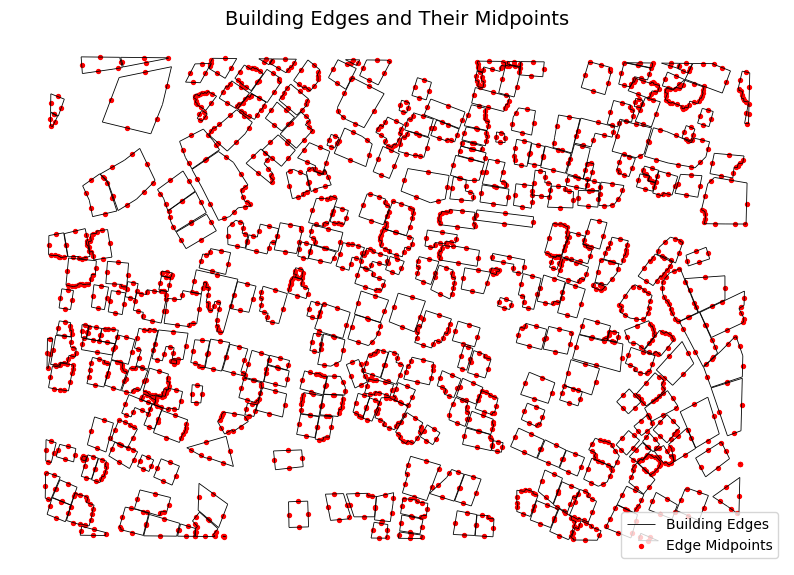

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load data
edges = gpd.read_file("building_edges.shp")
midpoints = gpd.read_file("building_edge_midpoints.shp")

# Create plot
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Plot building edges
edges.plot(
    ax=ax,
    linewidth=0.6,
    edgecolor="black",
    label="Building Edges"
)

# Plot edge midpoints
midpoints.plot(
    ax=ax,
    color="red",
    markersize=8,
    label="Edge Midpoints"
)

# Styling
ax.set_title("Building Edges and Their Midpoints", fontsize=14)
ax.set_axis_off()
ax.legend()

plt.show()


In [ ]:
import pandas as pd
from shapely.ops import nearest_points
roads = gpd.read_file("road.shp")
midpoints_gdf = midpoints_gdf.to_crs(roads.crs)

# Compute the nearest road for each midpoint and its distance
nearest_road_ids = []
nearest_distances = []

for idx, midpoint in midpoints_gdf.iterrows():
    # Calculate distances to all roads
    distances = roads.distance(midpoint.geometry)
    min_dist_idx = distances.idxmin()
    nearest_road_ids.append(min_dist_idx)
    nearest_distances.append(distances[min_dist_idx])
midpoints_gdf["nearest_road_id"] = nearest_road_ids
midpoints_gdf["road_dist"] = nearest_distances

selected_midpoints = (
    midpoints_gdf
    .sort_values("road_dist")
    .groupby(["building_id", "nearest_road_id"])
    .first()
    .reset_index()
)

selected_midpoints.to_file("selected_midpoints.shp")
print("Total selected midpoints:", len(selected_midpoints))


✅ DONE: Selected midpoints saved as 'selected_midpoints.shp'
Total selected midpoints: 488


/tmp/ipython-input-661212480.py:33: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  selected_midpoints.to_file("selected_midpoints.shp")
/usr/local/lib/python3.12/dist-packages/pyogrio/geopandas.py:917: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'building_id' to 'building_i'
  ogr_write(
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'nearest_road_id' to 'nearest_ro'
  ogr_write(


/tmp/ipython-input-3237267385.py:49: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


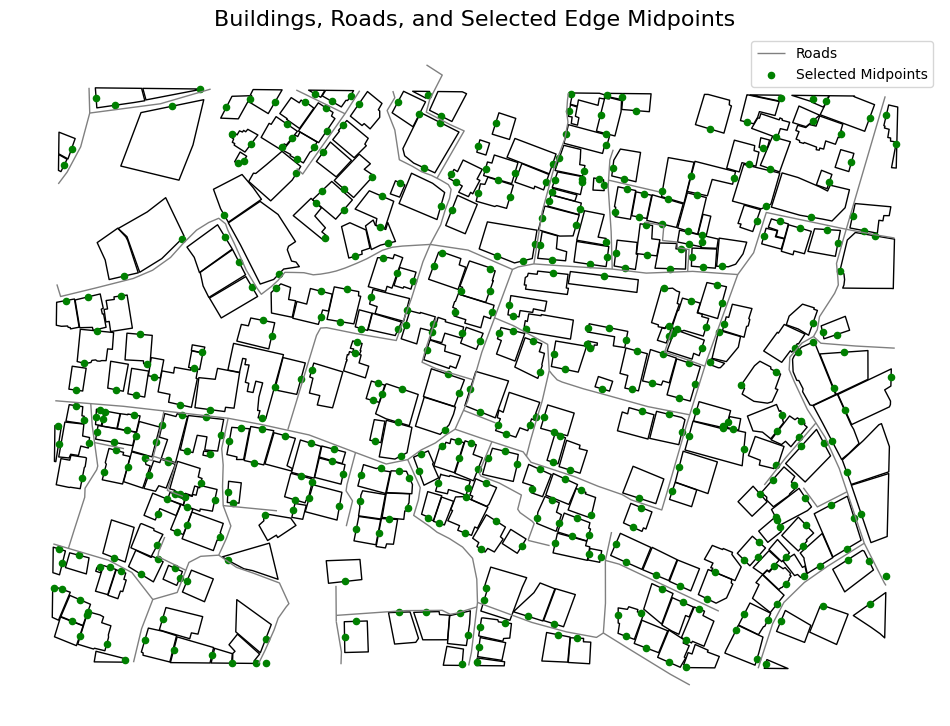

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# Load data
buildings = gpd.read_file("buildings.shp")  # original building polygons
roads = gpd.read_file("road.shp")           # road lines
selected_midpoints = gpd.read_file("selected_midpoints.shp")  # filtered midpoints

buildings = buildings.to_crs(roads.crs)

if selected_midpoints.crs is None:
    selected_midpoints.set_crs(roads.crs, inplace=True)
else:
    selected_midpoints = selected_midpoints.to_crs(roads.crs)

# Create plot
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

# Plot buildings
buildings.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1,
    label="Buildings"
)

# Plot roads
roads.plot(
    ax=ax,
    color="gray",
    linewidth=1,
    label="Roads"
)

# Plot selected midpoints
selected_midpoints.plot(
    ax=ax,
    color="green",
    markersize=20,
    label="Selected Midpoints"
)

# Styling
ax.set_title("Buildings, Roads, and Selected Edge Midpoints", fontsize=16)
ax.set_axis_off()
ax.legend()

plt.show()
